In [ ]:
import pandas as pd

Imported pandas so I will be able to work with table in python

In [ ]:
df= pd.read_csv("1__iris.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


read the uploaded documents and I viewed the first 5 rows



In [ ]:
df.shape

(150, 5)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


asked for more information on the dataframe.
It shows I have 150 entries


In [ ]:
df.isnull().sum()

,0
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


checked through the dataframe if there is  null input and sums it up.It shows that there is no empty input.

In [ ]:
df.duplicated().sum()

np.int64(3)

checks if there are duplicates. There are 3 duplicated rows

In [ ]:
df= df.drop_duplicates()
df.shape

(147, 5)

dropped all the duplicated rows so as not to cause confusion

In [ ]:
df["species"].value_counts()

,count
species,
versicolor,50
virginica,49
setosa,48


Counted the value of each species.

In [ ]:
X=df.drop("species", axis=1)
X.shape

(147, 4)

dropped the species column
and checked the shape of X

Now X has 147 rows and 4 columns

In [ ]:
X.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,147.000000,147.000000,147.000000,147.000000
mean,5.856463,3.055782,3.780272,1.208844
std,0.829100,0.437009,1.759111,0.757874
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.400000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Gives summary statistics for each column: count, mean,std,min,quartile and max



In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled.mean(axis=0).round(2))
print(X_scaled.std(axis=0).round(2))


[-0.  0. -0. -0.]
[1. 1. 1. 1.]


Okay so here I imported StandardScaler from scikit learn so as to treat the numbers the same way so no column dominates by size alone.
I fit_ transform the X. it studies trainind data and works out each column's average and spread and I use numbers to rescale the columns.
Found the mean and standard deviation


In [ ]:
from sklearn.cluster import KMeans
inertias=[]
for k in range(1,11):
  km=KMeans(n_clusters=k, n_init=10, random_state=42)
  km.fit(X_scaled)
  inertias.append(km.inertia_)
print(inertias)

[587.9999999999999, 220.8590794074236, 138.25771133117857, 112.90751031641206, 89.88758954783327, 80.84472918727108, 70.01312876653141, 62.10689241561548, 54.1086830551593, 48.73214297339095]


imports KMeans from scikit Learn cluster section
inertias... makes an empty list to collect the results
Makes a for loop that counts 1to 10 and stops before 11 nand the indented lines run once for each value of K.

KMeans.. builds a model that will look for k groups "n_init 10 means it tries 10 differenr random starting positions and keeps the best one, because the result depends a little on where  the centroid start "random_state" make it repeatable.

km.fit... studies the algorithm

km.inertia_ is the inertia of thet model(and the undersore means "learned from the data")


k=1 gives 588, which is 147 flowers x 4 cloumns. Inertia always falls as K rises.

In [ ]:
pd.Series(inertias, index=range(1, 11)).diff().round(1)

,0
1,NaN
2,-367.1
3,-82.6
4,-25.4
5,-23.0
6,-9.0
7,-10.8
8,-7.9
9,-8.0
10,-5.4


This subtracts each value of k of k from the one before it so that I can see how much inertia dropped at each step

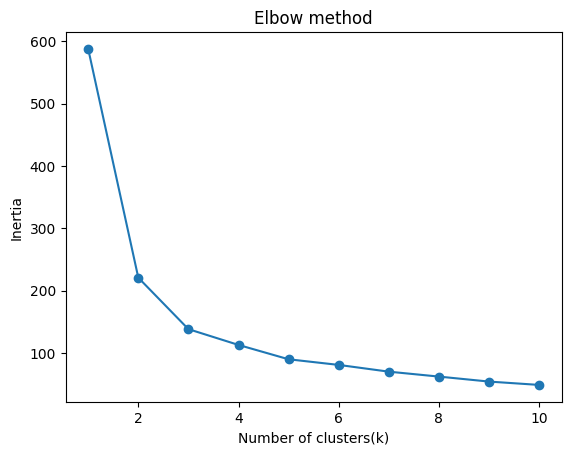

In [ ]:
import matplotlib.pyplot as plt
plt.plot(range(1,11), inertias,marker="o")
plt.xlabel("Number of clusters(k)")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.show()

This Imports matplotlib.pyplot as plt

Draws the line, with K along the bottom and inertia up the side, and dot at each K(marker="o")

I labeled the bottom axis ,side axiss and the title

plt.show() displays the chart

The curve falls steeply and then flattens, The elbow is the point where extra clusters stop giving big improvements

1 to 2 had a huge drop, 367

2 to 3 still had a big drop, 83

3 to 4, the drop shrinks to 25

After that, every steps only gains 5 to 23

The big gain stop after k =3 so the elbow is at 3 and that's the number of cluster I will use.

In [ ]:
kmeans=KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans.fit(X_scaled)
df["cluster"]=kmeans.labels_
df["cluster"].value_counts().sort_index()

,count
cluster,
0,52
1,48
2,47


Still the same code as what we use for the loop just here we build a model that will find exactly 3 groups

Kmeans.labels_ is a list with one number per flower saying which cluster that flower landed in. The order matches the rows of the table

that list is added to the table as a new column

In [ ]:
df.groupby("cluster")[list(X.columns)].mean().round(2)

,sepal_length,sepal_width,petal_length,petal_width
cluster,,,,
0,5.80,2.67,4.36,1.40
1,5.01,3.43,1.46,0.25
2,6.78,3.10,5.51,1.97


In [ ]:
pd.crosstab(df["species"], df["cluster"])

cluster,0,1,2
species,,,
setosa,0,48,0
versicolor,39,0,11
virginica,13,0,36


made a table of species vs the cluster that was made to compare the results gotten by the cluster with the actual one

This builds a table that counts how many flowers fall into each combinations

Setosa is perfectly seperated

Versicolor and Virginica are partly mixed.Cluster 0 holds 39 versicolor plus 13 virginica and cluster 2 holds 36 virginica and 11 versicolor. These two species overlap in their measurement so some flowers are at the border and K-mean only sees distance so can't tell the difference.

In total 123 out of 147 flowers which is 84%  are in the cluster that matches their species.


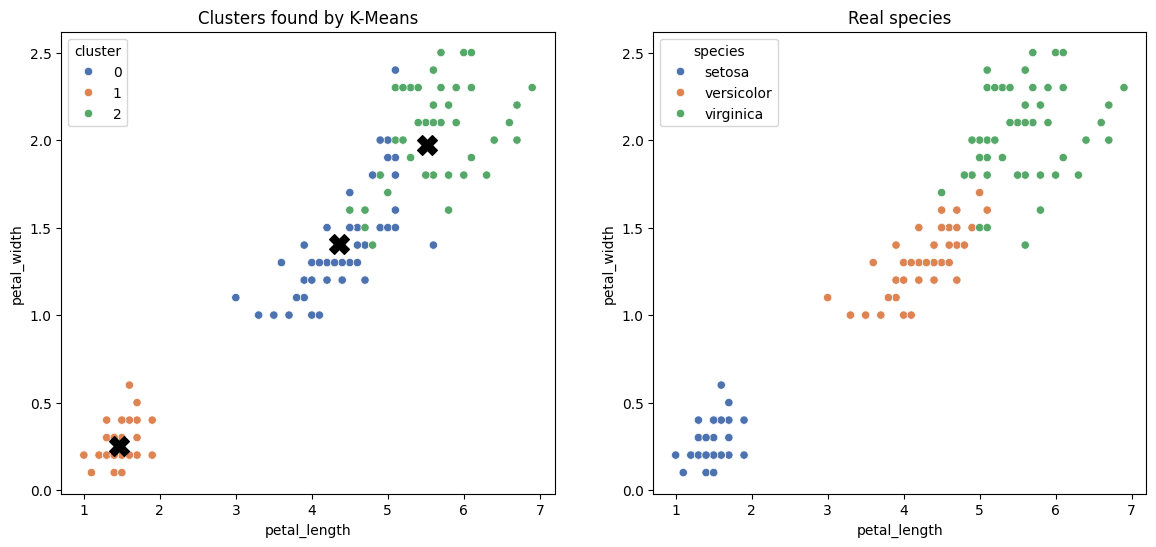

In [ ]:
import seaborn as sns

fig, axes = plt.subplots(1,2, figsize=(14, 6))

sns.scatterplot(data=df,x="petal_length",y="petal_width",hue="cluster", palette="deep", ax=axes[0])
centers = df.groupby("cluster")[["petal_length", "petal_width"]].mean()
axes[0].scatter(centers["petal_length"], centers["petal_width"], c="black", marker="X",s=200)
axes[0].set_title("Clusters found by K-Means")

sns.scatterplot(data=df, x="petal_length",y="petal_width", hue="species", palette="deep",ax=axes[1])
axes[1].set_title("Real species")

plt.show()

imports seaborn  a, charting library bulit on matplotlib that makes nicer statistical plots,

Draws 2 panels side by side  the first one is the cluster AND THE SECOND ONE ON THE RIGHT is the panel of the real species itself

The two panels looks very similar, with the same three blobs. The difference is afew dots at the border between versicolor and virginica, which means K-Means coloured differently from the true species. Those are the 24 flowers that didn't match.

In [ ]:
from sklearn.metrics import silhouette_score
silhouette_score(X_scaled, kmeans.labels_)

np.float64(0.4572716133419621)

The silhouette score measures how well each flower fits its own cluster compared with the next-nearest one.

for K =3, I got 0.46